In [13]:
from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [14]:
import os, json, time, random, shutil, warnings, glob, zipfile, math
from concurrent.futures import ThreadPoolExecutor
import numpy as np, pandas as pd, cv2, matplotlib.pyplot as plt, yaml
from scipy.optimize import linear_sum_assignment
from tqdm.auto import tqdm
import torch, torch.nn as nn, torch.nn.functional as F, torchvision

warnings.filterwarnings('ignore')
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

BASE_DIR = "/content/drive/MyDrive/lane detection"
DATA_DIR = f"{BASE_DIR}/data"
PROCESSED_DIR = f"{DATA_DIR}/processed"
MODELS_DIR = f"{BASE_DIR}/models"
RESULTS_DIR = f"{BASE_DIR}/results"
FIGURES_DIR = f"{RESULTS_DIR}/figures"
VIDEOS_DIR = f"{DATA_DIR}/videos"
CULANE_VIDEOS = f"{VIDEOS_DIR}/culane"
BDD_VIDEOS = f"{VIDEOS_DIR}/bdd"
DET_DIR = f"{BASE_DIR}/detections"
TRACK_DIR = f"{RESULTS_DIR}/tracking"
CLIPS_CSV = f"{VIDEOS_DIR}/bdd_clips.csv"
BDD_GT = f"{VIDEOS_DIR}/bdd_keyframe_gt.npz"
RESULTS_TRACK_CSV = f"{RESULTS_DIR}/results_tracking.csv"
TRACKER_YAML = f"{RESULTS_DIR}/tracker_best.yaml"
for d in [FIGURES_DIR, CULANE_VIDEOS, BDD_VIDEOS, DET_DIR, TRACK_DIR]:
	os.makedirs(d, exist_ok=True)

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
DETECTOR_RUN = 'rowanchor_r18_640x224'
W, H = 640, 224
DS = {'culane': {'w': 1640, 'h': 590, 'crop': 236}, 'bdd': {'w': 1280, 'h': 720, 'crop': 302}}
LINE_WIDTH = {'culane': 30, 'bdd': 23}

N_ROWS, N_CELLS = 36, 120
ROWS = np.linspace(10, H - 1, N_ROWS).astype(int)
X_MIN, X_MAX = -0.25 * W, 1.25 * W
CELL = (X_MAX - X_MIN) / N_CELLS
MIN_ROWS = 4
MEAN = np.array([0.485, 0.456, 0.406], np.float32)
STD = np.array([0.229, 0.224, 0.225], np.float32)

THRESHOLD = yaml.safe_load(open(f"{MODELS_DIR}/{DETECTOR_RUN}/config.yaml"))['threshold']
SMOOTH = None
if os.path.exists(f"{RESULTS_DIR}/best_settings.json"):
	SMOOTH = json.load(open(f"{RESULTS_DIR}/best_settings.json"))['smooth']

ROWS3 = np.array([215, 150, 85])
CHI2_3 = 11.34
print('device:', DEVICE, '| detector threshold:', THRESHOLD, '| smoothing:', SMOOTH)

device: cuda | detector threshold: 0.4 | smoothing: 3


In [15]:
def resample(x, y):
	order = np.argsort(y)
	x = x[order]
	y = y[order]
	rows = np.arange(H)
	out = np.full(H, np.nan, np.float32)
	inside = (rows >= y[0]) & (rows <= y[-1])
	out[inside] = np.interp(rows[inside], y, x)
	return out

def to_orig(lanes, ds):
	c = DS[ds]
	x = lanes * c['w'] / W
	y = np.arange(H) * (c['h'] - c['crop']) / H + c['crop']
	return x, y

def draw(img, lanes, colors=((0, 255, 0), (255, 0, 0)), thickness=2):
	img = np.array(img)
	for k in range(2):
		rows = np.where(np.isfinite(lanes[k]))[0]
		if len(rows) > 1:
			points = np.stack([lanes[k][rows], rows], 1).round().astype(np.int32)
			cv2.polylines(img, [points], False, colors[k], thickness)
	return img

def lane_mask(x, ds):
	c = DS[ds]
	xo, yo = to_orig(x, ds)
	mask = np.zeros((c['h'] - c['crop'], c['w']), np.uint8)
	rows = np.where(np.isfinite(xo))[0]
	if len(rows) > 1:
		points = np.stack([xo[rows], yo[rows] - c['crop']], 1).round().astype(np.int32)
		cv2.polylines(mask, [points], False, 1, LINE_WIDTH[ds])
	return mask

def iou(a, b):
	union = np.count_nonzero(a | b)
	if union == 0:
		return 0.0
	return np.count_nonzero(a & b) / union

def frame_ious(pred, gt, ds):
	pred_masks = []
	gt_masks = []
	for k in range(2):
		if np.isfinite(pred[k]).sum() > 1:
			pred_masks.append(lane_mask(pred[k], ds))
		else:
			pred_masks.append(None)
		if np.isfinite(gt[k]).sum() > 1:
			gt_masks.append(lane_mask(gt[k], ds))
		else:
			gt_masks.append(None)
	side = []
	for k in range(2):
		if pred_masks[k] is not None and gt_masks[k] is not None:
			side.append(iou(pred_masks[k], gt_masks[k]))
		else:
			side.append(np.nan)
	P = [m for m in pred_masks if m is not None]
	G = [m for m in gt_masks if m is not None]
	matched = []
	if len(P) > 0 and len(G) > 0:
		M = np.zeros((len(P), len(G)))
		for a in range(len(P)):
			for b in range(len(G)):
				M[a, b] = iou(P[a], G[b])
		r, c = linear_sum_assignment(-M)
		matched = list(M[r, c])
	return {'n_pred': len(P), 'n_gt': len(G), 'matched': matched, 'side': side,
	        'pred_on': [m is not None for m in pred_masks], 'gt_on': [m is not None for m in gt_masks]}

def prf(tp, fp, fn):
	if tp + fp + fn == 0:
		return np.nan, np.nan, np.nan
	p = tp / (tp + fp) if tp + fp > 0 else 0.0
	r = tp / (tp + fn) if tp + fn > 0 else 0.0
	f1 = 2 * p * r / (p + r) if p + r > 0 else 0.0
	return p, r, f1

def score(records, thr):
	tp, n_pred, n_gt = 0, 0, 0
	for r in records:
		tp += sum(m > thr for m in r['matched'])
		n_pred += r['n_pred']
		n_gt += r['n_gt']
	p, rec, f1 = prf(tp, n_pred - tp, n_gt - tp)
	out = {'precision': p, 'recall': rec, 'f1': f1}
	for k, name in enumerate(['left', 'right']):
		tp_side, pred_side, gt_side = 0, 0, 0
		for r in records:
			tp_side += r['side'][k] > thr
			pred_side += r['pred_on'][k]
			gt_side += r['gt_on'][k]
		out[f'f1_{name}'] = prf(tp_side, pred_side - tp_side, gt_side - tp_side)[2]
	return out

def f1_arrays(pred, gt, ds):
	with ThreadPoolExecutor(8) as pool:
		records = list(pool.map(frame_ious, pred, gt, [ds] * len(pred)))
	return score(records, 0.5)

In [16]:
CULANE_VIDEO_ZIP = f"{DATA_DIR}/culane/CULane/video_example.zip"
if len(os.listdir(CULANE_VIDEOS)) == 0:
	temp = '/content/culane_video_example'
	with zipfile.ZipFile(CULANE_VIDEO_ZIP) as z:
		z.extractall(temp)
	folders = {}
	for root, dirs, files in os.walk(temp):
		for f in sorted(files):
			path = os.path.join(root, f)
			if f.lower().endswith(('.mp4', '.avi', '.mov', '.mkv')):
				shutil.copy(path, f"{CULANE_VIDEOS}/{f}")
			elif f.lower().endswith(('.jpg', '.png')):
				folders.setdefault(root, []).append(path)
	for root, files in folders.items():
		if len(files) >= 30:
			first = cv2.imread(files[0])
			name = os.path.basename(root).replace('.', '_')
			writer = cv2.VideoWriter(f"{CULANE_VIDEOS}/{name}.mp4", cv2.VideoWriter_fourcc(*'mp4v'), 30, (first.shape[1], first.shape[0]))
			for f in files:
				writer.write(cv2.imread(f))
			writer.release()

for f in sorted(os.listdir(CULANE_VIDEOS)):
	cap = cv2.VideoCapture(f"{CULANE_VIDEOS}/{f}")
	print(f, '|', int(cap.get(cv2.CAP_PROP_FRAME_COUNT)), 'frames |', round(cap.get(cv2.CAP_PROP_FPS), 1), 'fps |',
	      int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), 'x', int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT)))
	cap.release()

05081544_0305.mp4 | 5400 frames | 30.0 fps | 1640 x 590


In [17]:
BDD_VIDEO_URL = "https://dl.cv.ethz.ch/bdd100k/data/bdd100k_videos_val_00.zip"
!wget -c -q --show-progress -P "{DATA_DIR}/bdd100k" "{BDD_VIDEO_URL}"

In [18]:
def to_rows(points, ds):
	c = DS[ds]
	return resample(points[:, 0] * W / c['w'], (points[:, 1] - c['crop']) * H / (c['h'] - c['crop']))

def pick_ego(lanes, min_row=H // 2):
	left, right = (None, -1e9), (None, 1e9)
	for x in lanes:
		rows = np.where(np.isfinite(x))[0]
		if len(rows) < 10 or rows[-1] < min_row:
			continue
		low = rows[-max(3, len(rows) // 3):]
		k, b = np.polyfit(low, x[low], 1)
		x_bottom = k * (H - 1) + b
		if x_bottom < W / 2 and x_bottom > left[1]:
			left = (x, x_bottom)
		if x_bottom >= W / 2 and x_bottom < right[1]:
			right = (x, x_bottom)
	empty = np.full(H, np.nan, np.float32)
	result = []
	for lane, _ in (left, right):
		if lane is None:
			result.append(empty)
		else:
			result.append(lane)
	return np.stack(result)

def merge_close(lanes, max_gap=10):
	merged = []
	for x in sorted(lanes, key=lambda x: -np.isfinite(x).sum()):
		joined = False
		for m in merged:
			both = np.isfinite(x) & np.isfinite(m)
			if both.sum() >= 3 and np.median(np.abs(x[both] - m[both])) < max_gap:
				fill = np.isfinite(x) & ~np.isfinite(m)
				m[fill] = x[fill]
				joined = True
				break
		if not joined:
			merged.append(x.copy())
	return merged

def bdd_lanes(entry):
	out = []
	for label in entry.get('labels') or []:
		a = label.get('attributes') or {}
		kind = str(a.get('laneType', label.get('category', '')))
		if a.get('laneDirection') != 'parallel' or 'crosswalk' in kind or 'curb' in kind:
			continue
		for poly in label.get('poly2d') or []:
			v = np.array(poly['vertices'], np.float32)
			if len(v) >= 2 and np.ptp(v[:, 1]) > 20:
				out.append(to_rows(v, 'bdd'))
	return merge_close(out)

def bdd_condition(a):
	if a.get('weather') in ('rainy', 'snowy', 'foggy'):
		return 'bad_weather'
	if a.get('timeofday') in ('night', 'dawn/dusk'):
		return a['timeofday'].replace('/', '_')
	if a.get('scene') == 'highway':
		return 'day_highway'
	return 'day_city'

video_zips = sorted(glob.glob(f"{DATA_DIR}/bdd100k/*video*val*.zip"))
clips = None
if os.path.exists(CLIPS_CSV):
	clips = pd.read_csv(CLIPS_CSV)
	print('BDD clips already chosen:', len(clips))
elif len(video_zips) > 0:
	with zipfile.ZipFile(f"{DATA_DIR}/bdd100k/archive.zip") as z:
		label_file = [n for n in z.namelist() if n.endswith('bdd100k_labels_images_val.json')][0]
		labels = json.load(z.open(label_file))
	test_names = set(os.path.basename(p) for p in pd.read_csv(f"{PROCESSED_DIR}/test_bdd/meta.csv").path)
	members = {}
	with zipfile.ZipFile(video_zips[0]) as zf:
		for n in zf.namelist():
			if n.lower().endswith('.mov'):
				members[os.path.splitext(os.path.basename(n))[0]] = n
	rows = []
	gts = {}
	for e in labels:
		stem = e['name'][:-4]
		if stem not in members or e['name'] in test_names:
			continue
		gt = pick_ego(bdd_lanes(e), int(0.3 * H))
		if not np.isfinite(gt).any():
			continue
		rows.append({'name': e['name'], 'stem': stem, 'member': members[stem], 'condition': bdd_condition(e.get('attributes') or {})})
		gts[e['name']] = gt
	candidates = pd.DataFrame(rows)
	print(len(members), 'videos in the zip |', len(candidates), 'usable')
	parts = []
	for condition, group in candidates.groupby('condition'):
		group = group.sample(frac=1, random_state=SEED)
		parts.append(group.iloc[:6].assign(split='val'))
		parts.append(group.iloc[6:18].assign(split='test'))
	clips = pd.concat(parts, ignore_index=True)
	np.savez_compressed(BDD_GT, names=clips.name.values, lanes=np.stack([gts[n] for n in clips.name]))
	clips.to_csv(CLIPS_CSV, index=False)
else:
	print('no BDD video zip found: the BDD parts will be skipped')

if clips is not None and len(video_zips) > 0:
	with zipfile.ZipFile(video_zips[0]) as zf:
		for _, row in tqdm(clips.iterrows(), total=len(clips), desc='extract BDD clips'):
			dst = f"{BDD_VIDEOS}/{row.stem}.mov"
			if not os.path.exists(dst):
				with zf.open(row.member) as src, open(dst, 'wb') as out:
					shutil.copyfileobj(src, out)
if clips is not None:
	print(clips.groupby(['split', 'condition']).size().unstack(0))

no BDD video zip found: the BDD parts will be skipped


In [19]:
class RowAnchorNet(nn.Module):
	def __init__(self, width=W, channels=96):
		super().__init__()
		resnet = torchvision.models.resnet18(weights=None)
		self.stage2 = nn.Sequential(resnet.conv1, resnet.bn1, resnet.relu, resnet.maxpool, resnet.layer1, resnet.layer2)
		self.stage3 = resnet.layer3
		self.stage4 = resnet.layer4
		self.reduce3 = nn.Conv2d(256, channels, 1)
		self.reduce4 = nn.Conv2d(512, channels, 1)
		self.row_embedding = nn.Parameter(torch.zeros(1, channels, N_ROWS, 1))
		features_per_row = channels * (width // 16)
		self.position_head = nn.Linear(features_per_row, 2 * N_CELLS)
		self.exist_head = nn.Linear(features_per_row, 2)
		self.aux_head = nn.Sequential(nn.Conv2d(128, 64, 3, padding=1), nn.ReLU(), nn.Conv2d(64, 3, 1))

	def forward(self, x):
		f2 = self.stage2(x)
		f3 = self.stage3(f2)
		f4 = self.stage4(f3)
		f = self.reduce3(f3) + F.interpolate(self.reduce4(f4), size=f3.shape[2:], mode='bilinear')
		f = F.interpolate(f, size=(N_ROWS, f.shape[3]), mode='bilinear')
		f = F.relu(f + self.row_embedding)
		f = f.permute(0, 2, 1, 3).flatten(2)
		position = self.position_head(f).reshape(-1, N_ROWS, 2, N_CELLS).transpose(1, 2)
		exist = self.exist_head(f).transpose(1, 2)
		return position, exist

detector = RowAnchorNet().to(DEVICE)
detector.load_state_dict(torch.load(f"{MODELS_DIR}/{DETECTOR_RUN}/best.pt", map_location=DEVICE), strict=False)
detector.eval()

def smooth_lanes(lanes, sigma, degree):
	out = np.full_like(lanes, np.nan)
	for i in range(len(lanes)):
		for k in range(2):
			rows = np.where(np.isfinite(lanes[i, k]))[0]
			if len(rows) > degree + 2:
				weights = 1 / (np.nan_to_num(sigma[i, k, rows], nan=5.0) + 1)
				coef = np.polyfit(rows, lanes[i, k, rows], degree, w=weights)
				top, bottom = rows.min(), rows.max()
				out[i, k, top:bottom + 1] = np.polyval(coef, np.arange(top, bottom + 1))
	return out

def to_lanes(mean, spread, prob, threshold):
	xs = X_MIN + (mean + 0.5) * CELL
	sig = spread * CELL
	n = len(mean)
	lanes = np.full((n, 2, H), np.nan, np.float32)
	sigma = np.full((n, 2, H), np.nan, np.float32)
	conf = np.zeros((n, 2), np.float32)
	for i in range(n):
		for k in range(2):
			on = prob[i, k] > threshold
			if on.sum() >= MIN_ROWS:
				lanes[i, k] = resample(xs[i, k, on], ROWS[on])
				sigma[i, k] = resample(sig[i, k, on], ROWS[on])
				conf[i, k] = prob[i, k, on].mean()
	if SMOOTH is not None:
		lanes = smooth_lanes(lanes, sigma, SMOOTH)
	return lanes, conf, sigma

def prep_frame(frame, ds):
	h = frame.shape[0]
	top = int(round(h * DS[ds]['crop'] / DS[ds]['h']))
	img = cv2.resize(frame[top:], (W, H), interpolation=cv2.INTER_AREA)
	return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

@torch.no_grad()
def run_detector(batch):
	x = np.stack([(b / 255.0 - MEAN) / STD for b in batch]).transpose(0, 3, 1, 2)
	x = torch.tensor(x, dtype=torch.float32, device=DEVICE)
	if DEVICE == 'cuda':
		with torch.autocast('cuda', dtype=torch.float16):
			position, exist = detector(x)
	else:
		position, exist = detector(x)
	p = position.float().softmax(-1)
	cells = torch.arange(N_CELLS, device=DEVICE)
	mean = (p * cells).sum(-1)
	spread = ((p * (cells - mean[..., None]) ** 2).sum(-1)).sqrt()
	return mean.cpu().numpy(), spread.cpu().numpy(), exist.float().sigmoid().cpu().numpy()

def detect_video(name, path, ds, seconds):
	out_path = f"{DET_DIR}/{name}.npz"
	cap = cv2.VideoCapture(path)
	fps = cap.get(cv2.CAP_PROP_FPS) or 30.0
	total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
	max_frames = int(seconds * fps)
	expected = min(total, max_frames)
	if os.path.exists(out_path):
		cached = len(np.load(out_path)['lanes'])
		if cached >= expected - 5:
			cap.release()
			return
		print(name, 'cached detection is too short (', cached, 'frames ), redoing it')
		os.remove(out_path)
	batch, means, spreads, probs = [], [], [], []
	count = 0
	while count < max_frames:
		ok, frame = cap.read()
		if not ok:
			break
		batch.append(prep_frame(frame, ds))
		count += 1
		if len(batch) == 64:
			m, s, p = run_detector(batch)
			means.append(m)
			spreads.append(s)
			probs.append(p)
			batch = []
	if len(batch) > 0:
		m, s, p = run_detector(batch)
		means.append(m)
		spreads.append(s)
		probs.append(p)
	cap.release()
	if count == 0:
		print(name, 'could not be read, skipped')
		return
	lanes, conf, sigma = to_lanes(np.concatenate(means), np.concatenate(spreads), np.concatenate(probs), THRESHOLD)
	temp = f"{DET_DIR}/{name}_tmp.npz"
	np.savez_compressed(temp, lanes=lanes, conf=conf, sigma=sigma, fps=np.array(fps))
	os.replace(temp, out_path)
	print(name, 'detected', count, 'frames')

videos = []
for f in sorted(os.listdir(CULANE_VIDEOS)):
	videos.append({'name': 'culane_' + os.path.splitext(f)[0], 'path': f"{CULANE_VIDEOS}/{f}", 'ds': 'culane', 'split': 'test', 'seconds': 180})
if clips is not None:
	for _, row in clips.iterrows():
		videos.append({'name': 'bdd_' + row.stem, 'path': f"{BDD_VIDEOS}/{row.stem}.mov", 'ds': 'bdd', 'split': row.split, 'seconds': 20})
videos = pd.DataFrame(videos)
for _, v in tqdm(videos.iterrows(), total=len(videos), desc='detect'):
	if os.path.exists(v.path):
		detect_video(v['name'], v.path, v.ds, v.seconds)
print(len(os.listdir(DET_DIR)), 'videos with cached detections')
display(videos[['name', 'ds', 'split', 'seconds']])

detect:   0%|          | 0/1 [00:00<?, ?it/s]

culane_05081544_0305 detected 5400 frames
1 videos with cached detections


,name,ds,split,seconds
0,culane_05081544_0305,culane,test,180


In [20]:
F_MAT = np.eye(6)
F_MAT[:3, 3:] = np.eye(3)
H_MAT = np.hstack([np.eye(3), np.zeros((3, 3))])

FULL = {'q_pos': 2.0, 'q_vel': 0.5, 'r0': 9.0, 'use_sigma': True, 'gate': True, 'gate_chi2': CHI2_3,
        'swap_fix': True, 'width_coupling': True, 'confirm_hits': 3, 'max_coast': 15, 'lane_change': True, 'adaptive_q': True}

def measure(lane, conf, sigma, cfg):
	rows = np.where(np.isfinite(lane))[0]
	if len(rows) < 8 or rows.max() < ROWS3[1]:
		return None
	coef = np.polyfit(rows, lane[rows], 2)
	z = np.polyval(coef, ROWS3)
	if cfg['use_sigma'] and np.isfinite(sigma[rows]).any():
		s = np.interp(ROWS3, rows, np.nan_to_num(sigma[rows], nan=5.0))
		R = np.diag(s ** 2 + 1.0)
	else:
		R = np.eye(3) * cfg['r0'] / max(float(conf), 0.05)
	return {'z': z, 'R': R, 'top': int(rows.min())}

def curve_from_points(points, top):
	out = np.full(H, np.nan, np.float32)
	coef = np.polyfit(ROWS3, points, 2)
	top = int(max(0, top))
	out[top:] = np.polyval(coef, np.arange(top, H))
	return out

class LineTrack:
	def __init__(self, m, confirmed):
		self.x = np.concatenate([m['z'], np.zeros(3)])
		self.P = np.diag([25.0, 25.0, 25.0, 4.0, 4.0, 4.0])
		self.hits = 1
		self.misses = 0
		self.rejects = 0
		self.q_scale = 1.0
		self.top = m['top']
		self.confirmed = confirmed

	def predict(self, cfg):
		Q = np.diag([cfg['q_pos']] * 3 + [cfg['q_vel']] * 3) * self.q_scale
		self.x = F_MAT @ self.x
		self.P = F_MAT @ self.P @ F_MAT.T + Q

	def distance(self, m):
		y = m['z'] - H_MAT @ self.x
		S = H_MAT @ self.P @ H_MAT.T + m['R']
		return float(y @ np.linalg.solve(S, y))

	def update(self, m):
		y = m['z'] - H_MAT @ self.x
		S = H_MAT @ self.P @ H_MAT.T + m['R']
		K = self.P @ H_MAT.T @ np.linalg.inv(S)
		self.x = self.x + K @ y
		self.P = (np.eye(6) - K @ H_MAT) @ self.P
		self.top = m['top']

class KalmanTracker:
	def __init__(self, cfg):
		self.cfg = cfg
		self.tracks = [None, None]
		self.width = None
		self.events = {'gated': 0, 'swaps_fixed': 0, 'filled': 0, 'lane_changes': 0}

	def step(self, lanes, conf, sigma):
		cfg = self.cfg
		for t in self.tracks:
			if t is not None:
				t.predict(cfg)
		m = [measure(lanes[k], conf[k], sigma[k], cfg) for k in range(2)]
		left, right = self.tracks
		if cfg['swap_fix'] and left is not None and right is not None and m[0] is not None and m[1] is not None:
			same = left.distance(m[0]) + right.distance(m[1])
			swapped = left.distance(m[1]) + right.distance(m[0])
			if swapped < same:
				m = [m[1], m[0]]
				self.events['swaps_fixed'] += 1
		real = [m[0] is not None, m[1] is not None]
		if cfg['width_coupling'] and self.width is not None:
			for k in range(2):
				other = 1 - k
				if m[k] is None and m[other] is not None and self.tracks[k] is not None:
					sign = -1 if k == 0 else 1
					m[k] = {'z': m[other]['z'] + sign * self.width, 'R': m[other]['R'] * 4, 'top': m[other]['top']}
					self.events['filled'] += 1

		for k in range(2):
			t = self.tracks[k]
			if m[k] is None:
				if t is not None:
					t.misses += 1
					if t.misses > cfg['max_coast'] or not t.confirmed:
						self.tracks[k] = None
				continue
			if t is None:
				if real[k]:
					self.tracks[k] = LineTrack(m[k], cfg['confirm_hits'] <= 1)
				continue
			d2 = t.distance(m[k])
			if cfg['gate'] and t.confirmed and d2 > cfg['gate_chi2']:
				self.events['gated'] += 1
				t.rejects += 1
				t.misses += 1
				if cfg['adaptive_q']:
					t.q_scale = 4.0
				if t.rejects >= 3 and real[k]:
					self.tracks[k] = LineTrack(m[k], True)
				elif t.misses > cfg['max_coast']:
					self.tracks[k] = None
				continue
			t.update(m[k])
			t.rejects = 0
			t.misses = 0
			t.hits += 1
			if t.hits >= cfg['confirm_hits']:
				t.confirmed = True
			if cfg['adaptive_q']:
				if d2 > cfg['gate_chi2'] / 2:
					t.q_scale = min(t.q_scale * 2, 8.0)
				else:
					t.q_scale = max(t.q_scale / 2, 1.0)

		left, right = self.tracks
		if left is not None and right is not None and real[0] and real[1]:
			w = right.x[:3] - left.x[:3]
			if self.width is None:
				self.width = w
			else:
				self.width = 0.9 * self.width + 0.1 * w

		if cfg['lane_change']:
			left, right = self.tracks
			if left is not None and left.x[0] > W / 2:
				self.tracks = [None, left]
				self.events['lane_changes'] += 1
			elif right is not None and right.x[0] < W / 2:
				self.tracks = [right, None]
				self.events['lane_changes'] += 1

		out = np.full((2, H), np.nan, np.float32)
		coasting = [False, False]
		for k in range(2):
			t = self.tracks[k]
			if t is not None and t.confirmed:
				out[k] = curve_from_points(t.x[:3], t.top)
				coasting[k] = t.misses > 0
		return out, coasting

class SimpleTracker:
	def __init__(self, cfg):
		self.alpha = cfg['alpha']
		self.hold = cfg['hold']
		self.state = [None, None]
		self.misses = [0, 0]
		self.top = [0, 0]
		self.events = {}

	def step(self, lanes, conf, sigma):
		out = np.full((2, H), np.nan, np.float32)
		coasting = [False, False]
		for k in range(2):
			m = measure(lanes[k], conf[k], sigma[k], {'use_sigma': False, 'r0': 1.0})
			if m is not None:
				if self.state[k] is None:
					self.state[k] = m['z']
				else:
					self.state[k] = self.alpha * m['z'] + (1 - self.alpha) * self.state[k]
				self.misses[k] = 0
				self.top[k] = m['top']
			elif self.state[k] is not None:
				self.misses[k] += 1
				if self.misses[k] > self.hold:
					self.state[k] = None
			if self.state[k] is not None:
				out[k] = curve_from_points(self.state[k], self.top[k])
				coasting[k] = self.misses[k] > 0
		return out, coasting

class NoTracker:
	def __init__(self, cfg):
		self.events = {}

	def step(self, lanes, conf, sigma):
		return lanes, [False, False]

def make_tracker(kind, cfg):
	if kind == 'none':
		return NoTracker(cfg)
	if kind == 'simple':
		return SimpleTracker(cfg)
	return KalmanTracker(cfg)

def run_sequence(kind, cfg, det):
	tracker = make_tracker(kind, cfg)
	T = len(det['lanes'])
	out = np.full((T, 2, H), np.nan, np.float32)
	coast = np.zeros((T, 2), bool)
	for t in range(T):
		out[t], coast[t] = tracker.step(det['lanes'][t], det['conf'][t], det['sigma'][t])
	return out, coast, tracker.events

30 tuning sequences | 50 test sequences


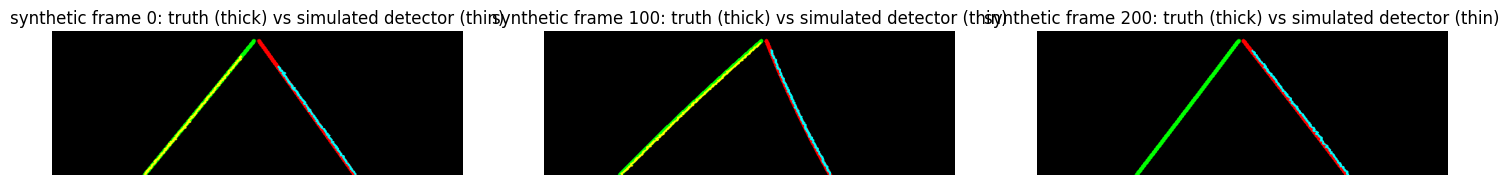

In [21]:
VP_ROW = 10

def gt_lane(bottom_x, vx, curv):
	rows = np.arange(H)
	x = vx + (bottom_x - vx) * (rows - VP_ROW) / (H - 1 - VP_ROW) + curv * ((H - 1 - rows) / (H - 1)) ** 2
	x[:15] = np.nan
	return x.astype(np.float32)

def make_sequence(seed, frames=300):
	rng = np.random.default_rng(seed)
	width = rng.uniform(260, 340)
	p = (rng.uniform(0.3, 0.7)) * width
	p_vel = 0.0
	curv = 0.0
	maneuver = 0
	gt = np.full((frames, 2, H), np.nan, np.float32)
	for t in range(frames):
		if maneuver == 0 and rng.random() < 0.005:
			maneuver = 50 if rng.random() < 0.5 else -50
		center = (math.floor(p / width) + 0.5) * width
		if maneuver != 0:
			p_vel = 0.8 * p_vel + 0.2 * np.sign(maneuver) * width / 50
			maneuver -= int(np.sign(maneuver))
		else:
			p_vel = 0.95 * p_vel + rng.normal(0, 0.15) - 0.003 * (p - center)
		p += p_vel
		curv = float(np.clip(0.99 * curv + rng.normal(0, 1.5), -120, 120))
		vx = W / 2 + 0.3 * curv
		k_left = math.floor(p / width)
		left_x = W / 2 + k_left * width - p
		right_x = left_x + width
		gt[t, 0] = gt_lane(left_x, vx, curv)
		gt[t, 1] = gt_lane(right_x, vx, curv)
	return gt

def simulate_detector(gt, seed):
	rng = np.random.default_rng(seed + 1000)
	T = len(gt)
	lanes = gt.copy()
	sigma = np.full_like(gt, 3.0)
	conf = rng.uniform(0.6, 1.0, (T, 2)).astype(np.float32)
	for t in range(T):
		for k in range(2):
			lanes[t, k] += rng.normal(0, 2.0) + rng.normal(0, 1.0, H)
			lanes[t, k, :int(rng.integers(15, 60))] = np.nan
	for k in range(2):
		t = 0
		while t < T:
			if rng.random() < 0.02:
				length = int(rng.integers(1, 26))
				lanes[t:t + length, k] = np.nan
				t += length
			else:
				t += 1
	for t in range(T):
		for k in range(2):
			if rng.random() < 0.02:
				lanes[t, k] += rng.choice([-1, 1]) * rng.uniform(60, 120)
				conf[t, k] = rng.uniform(0.4, 0.8)
		if rng.random() < 0.01:
			lanes[t] = lanes[t, ::-1].copy()
			conf[t] = conf[t, ::-1].copy()
	return {'lanes': lanes, 'conf': conf, 'sigma': sigma}

SYN_VAL = []
for seed in range(30):
	gt = make_sequence(seed)
	SYN_VAL.append({'gt': gt, 'det': simulate_detector(gt, seed)})
SYN_TEST = []
for seed in range(100, 150):
	gt = make_sequence(seed)
	SYN_TEST.append({'gt': gt, 'det': simulate_detector(gt, seed)})
print(len(SYN_VAL), 'tuning sequences |', len(SYN_TEST), 'test sequences')

frame = np.zeros((H, W, 3), np.uint8)
plt.figure(figsize=(18, 3))
for j, t in enumerate([0, 100, 200]):
	img = draw(frame, SYN_TEST[0]['gt'][t], thickness=6)
	img = draw(img, SYN_TEST[0]['det']['lanes'][t], colors=((255, 255, 0), (0, 255, 255)))
	plt.subplot(1, 3, j + 1)
	plt.imshow(img)
	plt.title(f'synthetic frame {t}: truth (thick) vs simulated detector (thin)')
	plt.axis('off')
plt.show()

In [22]:
def jitter(lanes):
	x = lanes[:, :, ROWS3]
	d = np.abs(np.diff(x, axis=0))
	return float(np.nanmean(d)) if np.isfinite(d).any() else np.nan

def count_swaps(lanes):
	near = lanes[:, :, ROWS3[0]]
	count = 0
	for t in range(1, len(near)):
		l, r = near[t]
		pl, pr = near[t - 1]
		if np.isfinite([l, r, pl, pr]).all():
			if abs(l - pr) < abs(l - pl) and abs(r - pl) < abs(r - pr):
				count += 1
	return count

def evaluate_synthetic(kind, cfg, sequences, step=3, drop=None):
	preds, gts, jit, both, coast = [], [], [], [], []
	swaps, frames = 0, 0
	for seq in sequences:
		det = seq['det']
		if drop is not None:
			det = {'lanes': det['lanes'].copy(), 'conf': det['conf'], 'sigma': det['sigma']}
			det['lanes'][drop[0]:drop[0] + drop[1]] = np.nan
		out, coasting, events = run_sequence(kind, cfg, det)
		if drop is None:
			preds.append(out[::step])
			gts.append(seq['gt'][::step])
		else:
			end = drop[0] + max(drop[1], 1)
			preds.append(out[drop[0]:end])
			gts.append(seq['gt'][drop[0]:end])
		jit.append(jitter(out))
		swaps += count_swaps(out)
		frames += len(out)
		both.append(np.isfinite(out).any(2).all(1).mean())
		coast.append(coasting.mean())
	s = f1_arrays(np.concatenate(preds), np.concatenate(gts), 'culane')
	return {'f1': s['f1'], 'f1_left': s['f1_left'], 'f1_right': s['f1_right'], 'jitter': np.nanmean(jit),
	        'wrong_swaps_per_1000': 1000 * swaps / frames, 'both_lines_pct': 100 * np.mean(both), 'coasted_pct': 100 * np.mean(coast)}

def load_detection(name):
	d = np.load(f"{DET_DIR}/{name}.npz")
	return {'lanes': d['lanes'], 'conf': d['conf'], 'sigma': d['sigma'], 'fps': float(d['fps'])}

BDD_TRUTH = {}
if os.path.exists(BDD_GT):
	truth = np.load(BDD_GT, allow_pickle=True)
	for name, lanes in zip(truth['names'], truth['lanes']):
		BDD_TRUTH['bdd_' + name[:-4]] = lanes

def evaluate_bdd(kind, cfg, split, drop=0):
	preds, gts, jit, both, coast = [], [], [], [], []
	swaps, frames = 0, 0
	for _, v in videos[(videos.ds == 'bdd') & (videos.split == split)].iterrows():
		if not os.path.exists(f"{DET_DIR}/{v['name']}.npz") or v['name'] not in BDD_TRUTH:
			continue
		det = load_detection(v['name'])
		key = int(round(10 * det['fps']))
		if key >= len(det['lanes']):
			continue
		if drop > 0:
			det['lanes'] = det['lanes'].copy()
			det['lanes'][key - drop + 1:key + 1] = np.nan
		out, coasting, events = run_sequence(kind, cfg, det)
		preds.append(out[key])
		gts.append(BDD_TRUTH[v['name']])
		jit.append(jitter(out))
		swaps += count_swaps(out)
		frames += len(out)
		both.append(np.isfinite(out).any(2).all(1).mean())
		coast.append(coasting.mean())
	if len(preds) == 0:
		return None
	s = f1_arrays(np.stack(preds), np.stack(gts), 'bdd')
	return {'f1': s['f1'], 'f1_left': s['f1_left'], 'f1_right': s['f1_right'], 'jitter': np.nanmean(jit),
	        'wrong_swaps_per_1000': 1000 * swaps / frames, 'both_lines_pct': 100 * np.mean(both), 'coasted_pct': 100 * np.mean(coast), 'clips': len(preds)}

def evaluate_videos(kind, cfg, ds, split):
	jit, both, coast = [], [], []
	swaps, frames = 0, 0
	for _, v in videos[(videos.ds == ds) & (videos.split == split)].iterrows():
		if not os.path.exists(f"{DET_DIR}/{v['name']}.npz"):
			continue
		out, coasting, events = run_sequence(kind, cfg, load_detection(v['name']))
		jit.append(jitter(out))
		swaps += count_swaps(out)
		frames += len(out)
		both.append(np.isfinite(out).any(2).all(1).mean())
		coast.append(coasting.mean())
	if frames == 0:
		return None
	return {'jitter': np.nanmean(jit), 'wrong_swaps_per_1000': 1000 * swaps / frames,
	        'both_lines_pct': 100 * np.mean(both), 'coasted_pct': 100 * np.mean(coast), 'videos': len(jit)}

In [23]:
if os.path.exists(TRACKER_YAML):
	BEST = yaml.safe_load(open(TRACKER_YAML))
	print('tracker already tuned:', BEST)
else:
	grid_rows = []
	best_score = -1e9
	BEST = None
	for q_pos in [0.5, 2.0, 8.0]:
		for q_vel in [0.1, 0.5]:
			for max_coast in [10, 30]:
				cfg = dict(FULL, q_pos=q_pos, q_vel=q_vel, max_coast=max_coast)
				syn = evaluate_synthetic('kalman', cfg, SYN_VAL)
				value = syn['f1'] - 0.02 * syn['jitter'] - 0.001 * syn['wrong_swaps_per_1000']
				bdd = evaluate_bdd('kalman', cfg, 'val')
				if bdd is not None:
					value += bdd['f1']
				grid_rows.append({'q_pos': q_pos, 'q_vel': q_vel, 'max_coast': max_coast, 'syn_f1': syn['f1'], 'syn_jitter': syn['jitter'],
				                  'bdd_val_f1': None if bdd is None else bdd['f1'], 'score': value})
				print(grid_rows[-1])
				if value > best_score:
					best_score = value
					BEST = cfg
	pd.DataFrame(grid_rows).to_csv(f"{TRACK_DIR}/grid_search.csv", index=False)
	yaml.safe_dump({k: (float(v) if isinstance(v, (np.floating, float)) else v) for k, v in BEST.items()}, open(TRACKER_YAML, 'w'))
	print('best tracker:', BEST)

tracker already tuned: {'adaptive_q': True, 'confirm_hits': 3, 'gate': True, 'gate_chi2': 11.34, 'lane_change': True, 'max_coast': 30, 'q_pos': 0.5, 'q_vel': 0.1, 'r0': 9.0, 'swap_fix': True, 'use_sigma': True, 'width_coupling': True}


In [24]:
BASIC = dict(BEST, use_sigma=False, gate=False, swap_fix=False, width_coupling=False, confirm_hits=1, lane_change=False, adaptive_q=False)
VARIANTS = [('none', 'none', {}), ('simple', 'simple', {'alpha': 0.5, 'hold': 10}),
            ('kalman_basic', 'kalman', BASIC), ('kalman_full', 'kalman', BEST)]
ABLATIONS = [('no_sigma_noise', {'use_sigma': False}), ('no_gating', {'gate': False}), ('no_swap_fix', {'swap_fix': False}),
             ('no_width_coupling', {'width_coupling': False}), ('no_track_states', {'confirm_hits': 1, 'max_coast': 0}),
             ('no_lane_change', {'lane_change': False}), ('no_adaptive_q', {'adaptive_q': False})]
for name, change in ABLATIONS:
	VARIANTS.append(('full_' + name, 'kalman', dict(BEST, **change)))

rows = []
for name, kind, cfg in tqdm(VARIANTS, desc='variants'):
	result = evaluate_synthetic(kind, cfg, SYN_TEST)
	rows.append({'tracker': name, 'data': 'synthetic_test', **result})
	result = evaluate_bdd(kind, cfg, 'test')
	if result is not None:
		rows.append({'tracker': name, 'data': 'bdd_test_clips', **result})
	result = evaluate_videos(kind, cfg, 'culane', 'test')
	if result is not None:
		rows.append({'tracker': name, 'data': 'culane_test_videos', **result})

truth_jitter = np.nanmean([jitter(seq['gt']) for seq in SYN_TEST])
rows.append({'tracker': 'ground_truth_motion', 'data': 'synthetic_test', 'jitter': truth_jitter})

timing = {}
for name, kind, cfg in VARIANTS[:4]:
	start = time.time()
	frames = 0
	for seq in SYN_TEST[:10]:
		run_sequence(kind, cfg, seq['det'])
		frames += len(seq['gt'])
	timing[name] = 1000 * (time.time() - start) / frames
for r in rows:
	r['ms_per_frame_cpu'] = timing.get(r['tracker'], np.nan)

results = pd.DataFrame(rows)
results.to_csv(RESULTS_TRACK_CSV, index=False)
for data, table in results.groupby('data'):
	print(data)
	display(table.drop(columns='data').round(3))

variants:   0%|          | 0/11 [00:00<?, ?it/s]

culane_test_videos


,tracker,f1,f1_left,f1_right,jitter,wrong_swaps_per_1000,both_lines_pct,coasted_pct,ms_per_frame_cpu,videos
1,none,NaN,NaN,NaN,1.398,0.0,100.000,0.000,0.002,1.0
3,simple,NaN,NaN,NaN,1.025,0.0,100.000,0.093,0.622,1.0
5,kalman_basic,NaN,NaN,NaN,1.029,0.0,100.000,0.093,0.911,1.0
7,kalman_full,NaN,NaN,NaN,0.791,0.0,99.741,0.574,0.878,1.0
9,full_no_sigma_noise,NaN,NaN,NaN,1.007,0.0,99.704,2.694,NaN,1.0
11,full_no_gating,NaN,NaN,NaN,0.850,0.0,99.741,0.093,NaN,1.0
13,full_no_swap_fix,NaN,NaN,NaN,0.805,0.0,99.741,0.611,NaN,1.0
15,full_no_width_coupling,NaN,NaN,NaN,0.791,0.0,99.741,0.574,NaN,1.0
17,full_no_track_states,NaN,NaN,NaN,0.644,0.0,99.074,0.000,NaN,1.0
19,full_no_lane_change,NaN,NaN,NaN,0.801,0.0,99.963,0.602,NaN,1.0


synthetic_test


,tracker,f1,f1_left,f1_right,jitter,wrong_swaps_per_1000,both_lines_pct,coasted_pct,ms_per_frame_cpu,videos
0,none,0.860,0.849,0.853,10.367,12.667,61.867,0.000,0.002,NaN
2,simple,0.796,0.793,0.797,4.690,5.333,86.213,13.750,0.622,NaN
4,kalman_basic,0.743,0.739,0.746,5.226,0.733,99.633,20.680,0.911,NaN
6,kalman_full,0.974,0.971,0.976,1.821,0.000,97.767,6.553,0.878,NaN
8,full_no_sigma_noise,0.972,0.970,0.974,1.804,0.000,97.767,6.457,NaN,NaN
10,full_no_gating,0.844,0.843,0.844,3.722,0.000,94.940,3.317,NaN,NaN
12,full_no_swap_fix,0.973,0.971,0.975,1.834,0.000,97.727,7.167,NaN,NaN
14,full_no_width_coupling,0.919,0.921,0.917,1.903,0.000,96.580,22.417,NaN,NaN
16,full_no_track_states,0.929,0.924,0.934,1.466,0.000,80.573,0.000,NaN,NaN
18,full_no_lane_change,0.967,0.960,0.963,2.153,0.200,99.193,7.600,NaN,NaN


,tracker,gap_frames,synthetic_f1
0,none,0,0.886
1,none,5,0.000
2,none,15,0.000
3,none,30,0.000
4,none,60,0.000
5,simple,0,0.753
6,simple,5,0.679
7,simple,15,0.485
8,simple,30,0.298
9,simple,60,0.168


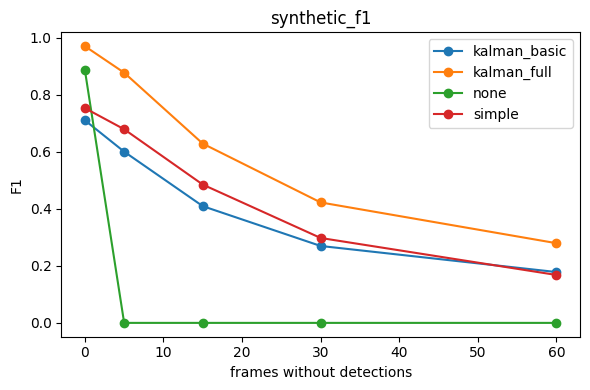

In [25]:
gaps = [0, 5, 15, 30, 60]
curve_rows = []
for name, kind, cfg in VARIANTS[:4]:
	for k in gaps:
		syn = evaluate_synthetic(kind, cfg, SYN_TEST, drop=(150, k))
		row = {'tracker': name, 'gap_frames': k, 'synthetic_f1': syn['f1']}
		bdd = evaluate_bdd(kind, cfg, 'test', drop=k)
		if bdd is not None:
			row['bdd_keyframe_f1'] = bdd['f1']
		curve_rows.append(row)
curve = pd.DataFrame(curve_rows)
curve.to_csv(f"{TRACK_DIR}/gap_curve.csv", index=False)
display(curve.round(3))

columns = [c for c in ['synthetic_f1', 'bdd_keyframe_f1'] if c in curve.columns]
plt.figure(figsize=(6 * len(columns), 4))
for j, column in enumerate(columns):
	plt.subplot(1, len(columns), j + 1)
	for name, table in curve.groupby('tracker'):
		plt.plot(table.gap_frames, table[column], marker='o', label=name)
	plt.xlabel('frames without detections')
	plt.ylabel('F1')
	plt.title(column)
	plt.legend()
plt.tight_layout()
plt.savefig(f"{FIGURES_DIR}/tracking_gap_curve.png", dpi=120)
plt.show()

In [26]:
choice = videos[(videos.ds == 'bdd') & (videos.split == 'test')]
if len(choice) == 0:
	choice = videos[videos.ds == 'culane']
v = choice.iloc[0]
det = load_detection(v['name'])
out, coasting, events = run_sequence('kalman', BEST, det)
cap = cv2.VideoCapture(v.path)
writer = cv2.VideoWriter(f"{TRACK_DIR}/{v['name']}_raw_vs_tracked.mp4", cv2.VideoWriter_fourcc(*'mp4v'), det['fps'], (2 * W, H))
for t in range(len(out)):
	ok, frame = cap.read()
	if not ok:
		break
	img = prep_frame(frame, v.ds)
	raw = draw(img, det['lanes'][t])
	tracked_colors = []
	for k in range(2):
		if coasting[t, k]:
			tracked_colors.append((255, 255, 255))
		else:
			tracked_colors.append(((0, 255, 0), (255, 0, 0))[k])
	tracked = draw(img, out[t], colors=tracked_colors)
	cv2.putText(raw, 'detector', (10, 25), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (255, 255, 255), 2)
	cv2.putText(tracked, 'tracker', (10, 25), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (255, 255, 255), 2)
	writer.write(cv2.cvtColor(np.hstack([raw, tracked]), cv2.COLOR_RGB2BGR))
writer.release()
cap.release()
print('saved', f"{TRACK_DIR}/{v['name']}_raw_vs_tracked.mp4", '| events:', events)

saved /content/drive/MyDrive/lane detection/results/tracking/culane_05081544_0305_raw_vs_tracked.mp4 | events: {'gated': 69, 'swaps_fixed': 8, 'filled': 0, 'lane_changes': 4}


In [27]:
drive.flush_and_unmount()
from google.colab import runtime
runtime.unassign()